# Semana 6 — Ordenación de datos y series temporales aplicado a Penonomé

Aplica las unidades 37 a 40 del curso: [ordenación de datos](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), [series temporales](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), [análisis de datos financieros](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) y el [miniproyecto de la pandemia](../../../../01-python/semana-06/clase-2-mini-proyectos/u40-pandemia-coronavirus.ipynb). Es también el notebook de cierre del proyecto.

[Proyecto](../../README.md) | [Anterior](s05-dinamica-backtracking-modulos-pandas.ipynb) | [Siguiente](../../README.md)

In [1]:
def verificar(descripcion, obtenido, esperado):
    """Compara el resultado de un ejercicio con el esperado e informa sin detener el notebook."""
    if obtenido == esperado:
        print(f"Correcto: {descripcion}")
    else:
        print(f"Incorrecto: {descripcion}. Se esperaba {esperado!r} y se obtuvo {obtenido!r}")

## Qué hace este notebook

| Sección | Unidad | Datos |
|---|---|---|
| 1. Datos ordenados: `pivot` y `melt` | u37 | base larga (tabla 99) y afectaciones de SINAPROC |
| 2. Ordenar y agrupar | u37 | Censo 2023 (tabla 01), base larga y afectaciones de SINAPROC |
| 3. Series temporales: réplicas por día | u38 | réplicas acumuladas del sismo (IGC-UP, según la prensa) |
| 4. Cambio porcentual, índice base 100 y correlación | u38, u39 | comunicados de SINAPROC y vulnerabilidad social por corregimiento (Censo 2023 y PNUD) |
| 5. Series irregulares y volatilidad | u38, u39 | cortes de réplicas |
| 6. Análisis final con gráficos | u39, u40 | todo lo anterior |

Las funciones de carga y de ayuda están en `penonome.analisis` (ver la sección 1 del [notebook de la semana 5](s05-dinamica-backtracking-modulos-pandas.ipynb)).

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

import penonome.analisis as an
from penonome.analisis import leer

print("pandas", pd.__version__)

pandas 3.1.1


## 1. Datos ordenados: la base larga, `pivot` y `melt`

Según la [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), una tabla está **ordenada** (*tidy data*) cuando cada variable es una columna, cada observación es una fila y cada valor ocupa una celda. La tabla `99_base_larga_todo.csv` del paquete sigue ese formato: una fila por dato, con su indicador, su fecha, su unidad y su fuente.

Primero se revisan los datos que faltan con `isnull().sum()`, como en la u37.

In [3]:
larga_original = leer("99_base_larga_todo.csv")
print(larga_original.shape)
print(larga_original.isnull().sum()[lambda s: s > 0])
print("Filas que borraría dropna():", len(larga_original) - len(larga_original.dropna()))

(460, 12)
distrito          20
corregimiento     40
nota             391
dtype: int64
Filas que borraría dropna(): 391


Los huecos de `distrito` y `corregimiento` no son datos perdidos: significan que el dato es del nivel superior (provincia o distrito). La columna `nota` es opcional. Por eso no se usa `dropna()`, que borraría 391 de las 460 filas, casi todas válidas, sino `fillna("")`, que hace `an.base_larga()`. Así esas columnas pueden formar parte de un índice.

Con `pivot` la tabla pasa a formato **ancho** (una fila por indicador, una columna por fecha), cómodo para leer; con `melt` vuelve al formato largo. Si ninguna fila se pierde ni se duplica, la ida y vuelta devuelve exactamente la tabla original.

In [4]:
larga = an.base_larga()
claves = ["provincia", "distrito", "corregimiento", "indicador", "fecha"]
print("Filas repetidas por clave:", larga.duplicated(claves).sum())

ancha = an.a_ancho(larga)                         # pivot: fecha pasa a columnas
print("Formato ancho:", ancha.shape, "->", ancha.notna().sum().sum(), "celdas con dato")
poblacion_ancha = ancha[ancha.index.get_level_values("indicador") == "poblacion"]
print(poblacion_ancha.droplevel(["provincia", "distrito", "indicador", "unidad"]).head(6))

de_vuelta = an.a_largo(ancha)                     # melt: las columnas vuelven a ser filas
verificar("ninguna clave repetida (pivot es posible)", int(larga.duplicated(claves).sum()), 0)
verificar("melt devuelve las 460 filas", len(de_vuelta), 460)
verificar("ida y vuelta pivot -> melt idéntica a la original", an.ordenar_larga(de_vuelta).equals(an.ordenar_larga(larga)), True)

Filas repetidas por clave: 0
Formato ancho: (440, 3) -> 460 celdas con dato
fecha                2000     2010     2023
corregimiento                              
Boca de Tucué         NaN      NaN   2090.0
Candelario Ovalle     NaN      NaN   3615.0
Cañaveral          6367.0   7517.0   9324.0
Chiguirí Arriba    8581.0  10018.0   7185.0
Coclé              3637.0   4100.0   5811.0
El Coco            4592.0   5605.0  11064.0
Correcto: ninguna clave repetida (pivot es posible)
Correcto: melt devuelve las 460 filas
Correcto: ida y vuelta pivot -> melt idéntica a la original


**Error común:** usar `pivot` cuando hay claves repetidas: lanza `ValueError: Index contains duplicate entries`. En ese caso se usa `pivot_table`, que agrega los repetidos (por defecto, con la media). Por eso la celda anterior comprueba primero que no haya duplicados.

El caso contrario aparece en la tabla de afectaciones de SINAPROC (`afectaciones_sinaproc_cocle.csv`). Tiene formato largo, pero sus columnas `subcategoria` y `desagregacion` significan cosas distintas según la categoría: en «Edad y sexo» son el grupo de edad y el sexo; en «Atención especial por nivel de daño», el nivel de daño y el grupo vulnerable. Para ordenarla se filtra una categoría, se renombran las columnas con lo que de verdad contienen, y `pivot` y `melt` la llevan de largo a ancho y de vuelta.

In [5]:
afect = an.afectaciones()
print(afect.shape, "->", afect["categoria"].nunique(), "categorías")

edades = ["Recién nacidos", "Niñez", "Adolescencia", "Adultos", "Adultos mayores"]
niveles = ["Total", "Moderado", "Parcial", "Leve", "Menor"]

edad = (afect[afect["categoria"] == "Edad y sexo"]
        .rename(columns={"subcategoria": "grupo_de_edad", "desagregacion": "sexo"})
        [["grupo_de_edad", "sexo", "valor"]])
ancha_edad = edad.pivot(index="grupo_de_edad", columns="sexo", values="valor").loc[edades]
print(ancha_edad)

de_vuelta_edad = ancha_edad.reset_index().melt(id_vars="grupo_de_edad", var_name="sexo", value_name="valor")
orden = ["grupo_de_edad", "sexo"]
verificar("edad y sexo: 5 grupos x 2 sexos = 10 filas", len(edad), 10)
verificar("melt devuelve la tabla de edad y sexo", de_vuelta_edad.sort_values(orden).reset_index(drop=True).equals(
    edad.sort_values(orden).reset_index(drop=True)), True)
verificar("las personas por edad y sexo suman las evaluadas", int(edad["valor"].sum()), 10199)

(40, 10) -> 6 categorías
sexo             Hombres  Mujeres
grupo_de_edad                    
Recién nacidos       172      151
Niñez               1090      897
Adolescencia         455      458
Adultos             2521     2720
Adultos mayores      873      862
Correcto: edad y sexo: 5 grupos x 2 sexos = 10 filas
Correcto: melt devuelve la tabla de edad y sexo
Correcto: las personas por edad y sexo suman las evaluadas


Con la categoría «Atención especial por nivel de daño» se puede responder una pregunta de vulnerabilidad: ¿cuántas personas con discapacidad hay por cada 100 viviendas de cada nivel de daño? `pivot_table` pone los grupos vulnerables en columnas y `join` agrega las viviendas evaluadas de cada nivel.

In [6]:
atencion = (afect[afect["categoria"] == "Atención especial por nivel de daño"]
            .rename(columns={"subcategoria": "nivel_de_daño", "desagregacion": "grupo"})
            .pivot_table(index="nivel_de_daño", columns="grupo", values="valor", aggfunc="sum")
            .loc[niveles])
viviendas_nivel = (afect[afect["categoria"] == "Viviendas por nivel de daño"]
                   .set_index("subcategoria")["valor"].loc[niveles].rename("viviendas"))
vulnerables = atencion.join(viviendas_nivel)
vulnerables["discapacidad_por_100_viviendas"] = (vulnerables["Personas con discapacidad"] / vulnerables["viviendas"] * 100).round(1)
print(vulnerables)
promedio = vulnerables["Personas con discapacidad"].sum() / vulnerables["viviendas"].sum() * 100
print(f"En toda la muestra evaluada: {promedio:.1f} personas con discapacidad por cada 100 viviendas")

verificar("las viviendas de los cinco niveles suman las evaluadas", int(vulnerables["viviendas"].sum()), 2531)
verificar("personas con discapacidad en viviendas evaluadas", int(vulnerables["Personas con discapacidad"].sum()), 431)
verificar("mujeres embarazadas en viviendas evaluadas", int(vulnerables["Mujeres embarazadas"].sum()), 21)

               Mujeres embarazadas  Personas con discapacidad  viviendas  \
nivel_de_daño                                                              
Total                            7                         77        414   
Moderado                         2                         14        147   
Parcial                         11                        314       1750   
Leve                             1                         13        145   
Menor                            0                         13         75   

               discapacidad_por_100_viviendas  
nivel_de_daño                                  
Total                                    18.6  
Moderado                                  9.5  
Parcial                                  17.9  
Leve                                      9.0  
Menor                                    17.3  
En toda la muestra evaluada: 17.0 personas con discapacidad por cada 100 viviendas
Correcto: las viviendas de los cinco niveles sum

Hay 17.0 personas con discapacidad por cada 100 viviendas evaluadas, pero no se reparten parejo: en las viviendas de nivel Total (18.6), Parcial (17.9) y Menor (17.3) la cifra ronda las 17 a 19, y en las de nivel Moderado (9.5) y Leve (9.0) es la mitad. Los grupos son desiguales: Parcial tiene 1,750 viviendas y Menor solo 75 (13 personas), y las 21 mujeres embarazadas son muy pocas para comparar niveles, porque con tan pocos casos las diferencias pueden ser azar.

**Clave:** `melt` pasa de ancho a largo (columnas a filas) y `pivot` de largo a ancho. Una tabla ordenada se filtra, agrupa y grafica sin tener que reescribir nombres de columnas; cuando las columnas de una tabla mezclan significados, el primer paso es ordenarla.

**Referencia:** [Unidad 37 — Ordenación de datos](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), secciones 2 a 8: definición de datos ordenados, `isnull`, `dropna` y `fillna`.

## 2. Ordenar y agrupar: `sort_values` y `groupby`

`groupby` divide una tabla en grupos, aplica una función a cada uno y junta los resultados ([Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb) y proyecto de la [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb)). El caso más útil del proyecto es el que pide el `LEEME` del paquete: los seis corregimientos creados por la Ley 296 de 2022 salieron de cinco corregimientos originales, así que para comparar 2010 con 2023 hay que agruparlos a los once como un solo bloque.

In [7]:
from penonome.carga import PADRES_LEY_296      # el diccionario padre -> hijos de la semana 1

tabla01 = an.poblacion_corregimientos()
del_bloque = set(PADRES_LEY_296) | {hijo for hijos in PADRES_LEY_296.values() for hijo in hijos}
grupo = tabla01.index.map(lambda clave: "Bloque Ley 296 (11 corregimientos)" if clave in del_bloque
                          else tabla01.loc[clave, "corregimiento"])

comparable = tabla01.groupby(grupo)[["pob_2000", "pob_2010", "pob_2023"]].sum()
comparable["crecimiento_2010_2023"] = ((comparable["pob_2023"] / comparable["pob_2010"] - 1) * 100).round(1)
comparable = comparable.sort_values("crecimiento_2010_2023", ascending=False)
comparable.index.name = "grupo"
print(comparable)

verificar("corregimientos que forman el bloque", len(del_bloque), 11)
verificar("población 2023 del bloque", int(comparable.loc["Bloque Ley 296 (11 corregimientos)", "pob_2023"]), 48786)
verificar("el agrupamiento conserva el total del distrito", int(comparable["pob_2023"].sum()), 104326)

                                    pob_2000  pob_2010  pob_2023  \
grupo                                                              
El Coco                               4592.0    5605.0     11064   
Coclé                                 3637.0    4100.0      5811   
Cañaveral                             6367.0    7517.0      9324   
Penonomé (cabecera)                  15841.0   21748.0     25836   
Río Grande                            2915.0    3117.0      3505   
Bloque Ley 296 (11 corregimientos)   39096.0   43650.0     48786   

                                    crecimiento_2010_2023  
grupo                                                      
El Coco                                              97.4  
Coclé                                                41.7  
Cañaveral                                            24.0  
Penonomé (cabecera)                                  18.8  
Río Grande                                           12.4  
Bloque Ley 296 (11 corregimientos) 

Agrupado, el bloque de los once corregimientos creció 11.8 % entre 2010 y 2023: ni se despobló (como sugerían Pajonal o Tulú por separado) ni creció como El Coco, que casi duplicó su población (+97.4 %). La cabecera creció 18.8 %.

`groupby` también resume la base larga: cuántos datos hay por nivel geográfico y por unidad de medida.

In [8]:
larga["nivel"] = "provincia"
larga.loc[larga["distrito"] != "", "nivel"] = "distrito"
larga.loc[larga["corregimiento"] != "", "nivel"] = "corregimiento"
por_nivel = larga.groupby("nivel").size().sort_values(ascending=False)
print(por_nivel)
print()
larga["tema"] = larga["indicador"].str.split("_").str[0]
por_tema = larga.groupby("tema").agg(datos=("valor", "size"), fechas=("fecha", "nunique"))
print(por_tema.sort_values("datos", ascending=False))

verificar("datos de nivel corregimiento en la base larga", int(por_nivel["corregimiento"]), 420)
verificar("el tema con más datos es el Censo 2023", por_tema["datos"].idxmax(), "censo")

nivel
corregimiento    420
distrito          20
provincia         20
dtype: int64

            datos  fechas
tema                     
censo         360       1
pnud           48       1
poblacion      36       3
superficie     16       1
Correcto: datos de nivel corregimiento en la base larga
Correcto: el tema con más datos es el Censo 2023


`groupby` también resume la tabla de afectaciones: las personas evaluadas por sexo y el número de datos de cada categoría.

In [9]:
por_sexo = afect[afect["categoria"] == "Edad y sexo"].groupby("desagregacion")["valor"].sum()
print(por_sexo)
print()
print(afect.groupby("categoria").agg(datos=("valor", "size"), corte=("corte", "max")))

verificar("hombres evaluados", int(por_sexo["Hombres"]), 5111)
verificar("mujeres evaluadas", int(por_sexo["Mujeres"]), 5088)
verificar("«Otras afectaciones» reúne 11 datos", int(afect.groupby("categoria").size()["Otras afectaciones"]), 11)

desagregacion
Hombres    5111
Mujeres    5088
Name: valor, dtype: int64

                                     datos       corte
categoria                                             
Atención especial                        2  2026-11-15
Atención especial por nivel de daño     10  2026-11-15
Cobertura                                2  2026-11-15
Edad y sexo                             10  2026-11-15
Otras afectaciones                      11  2026-11-25
Viviendas por nivel de daño              5  2026-11-15
Correcto: hombres evaluados
Correcto: mujeres evaluadas
Correcto: «Otras afectaciones» reúne 11 datos


**Error común:** en pandas 3, `groupby(...).sum()` sobre una tabla con columnas de texto intenta sumarlas y falla. Se seleccionan antes las columnas numéricas (como arriba) o se usa `numeric_only=True`, la misma adaptación que hizo la u38 con el ejemplo del PDF.

**Referencia:** [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb) (`sort_values`, estadísticas por columna) y [Unidad 38 — proyecto de la unidad](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb) (`groupby` y suma por grupo).

## 3. Series temporales: las réplicas del sismo por día

Las réplicas acumuladas localizadas por el IGC-UP son datos de prensa (`datos/analisis/replicas_acumuladas.csv`), no una tabla oficial: siete cortes entre el 10 de octubre y el 20 de noviembre de 2026, el último aproximado. `an.replicas()` los devuelve como una Serie con `DatetimeIndex` (con `pd.to_datetime`, como el ejemplo del petróleo WTI de la [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb)). Con ese índice se puede trocear por fecha, remuestrear y calcular estadísticas móviles.

**Supuesto:** entre dos cortes no se conoce el día a día. `resample("D").interpolate()` llena los días intermedios con una línea recta, es decir, supone un ritmo constante entre cortes. Es una forma de ver la serie, no un dato observado.

In [10]:
replicas = an.replicas()
print(type(replicas.index).__name__, replicas.index.min().date(), "a", replicas.index.max().date(), "|", len(replicas), "cortes")
print(replicas.loc["2026-11-01":"2026-11-10"])                  # troceado por fecha
print()
diaria = replicas.resample("D").interpolate()                    # un valor por día
nuevas = diaria.diff().dropna()                                  # réplicas nuevas por día
semanal = nuevas.resample("W").sum().round(0).astype(int)        # 'W' = semanas que acaban en domingo
print(semanal)

verificar("cortes de réplicas", len(replicas), 7)
verificar("la serie diaria tiene un valor por día entre el primer y el último corte", len(diaria), 42)
verificar("el remuestreo conserva los cortes (2 de noviembre)", int(diaria.loc["2026-11-02"]), 1271)
verificar("las réplicas nuevas por día suman el aumento total", int(round(nuevas.sum())), 1690 - 135)

DatetimeIndex 2026-10-10 a 2026-11-20 | 7 cortes
fecha
2026-11-02    1271
2026-11-06    1452
2026-11-09    1483
Name: replicas_acumuladas, dtype: int64

fecha
2026-10-11    102
2026-10-18    571
2026-10-25    216
2026-11-01    216
2026-11-08    233
2026-11-15    140
2026-11-22     77
Freq: W-SUN, Name: replicas_acumuladas, dtype: int64
Correcto: cortes de réplicas
Correcto: la serie diaria tiene un valor por día entre el primer y el último corte
Correcto: el remuestreo conserva los cortes (2 de noviembre)
Correcto: las réplicas nuevas por día suman el aumento total


In [11]:
media_movil = nuevas.rolling(window=7).mean()                    # media móvil de 7 días
semanal_pct = an.variacion_pct(diaria, periodos=7)               # crecimiento de las acumuladas frente a 7 días antes

resumen = pd.DataFrame({"acumuladas": diaria.round(0), "nuevas_por_dia": nuevas.round(1),
                        "media_movil_7d": media_movil.round(1), "crece_7d_pct": semanal_pct.round(1)})
print(resumen.loc["2026-11-14":"2026-11-20"])

verificar("shift(7) y pct_change(7) dan lo mismo",
          semanal_pct.dropna().round(6).tolist(), (diaria.pct_change(7) * 100).dropna().round(6).tolist())
verificar("la media móvil de 7 días empieza el 17 de octubre", str(media_movil.first_valid_index().date()), "2026-10-17")
verificar("media móvil de 7 días al 20 de noviembre (réplicas por día)", round(media_movil.iloc[-1], 1), 17.2)
verificar("las acumuladas crecieron 7.7 % en los 7 días hasta el 20 de noviembre", round(semanal_pct.iloc[-1], 1), 7.7)

            acumuladas  nuevas_por_dia  media_movil_7d  crece_7d_pct
fecha                                                               
2026-11-14      1591.0            21.6            18.4           8.8
2026-11-15      1613.0            21.6            20.0           9.5
2026-11-16      1634.0            21.6            21.6          10.2
2026-11-17      1656.0            21.6            21.6          10.1
2026-11-18      1667.0            11.3            20.2           9.2
2026-11-19      1679.0            11.3            18.7           8.4
2026-11-20      1690.0            11.3            17.2           7.7
Correcto: shift(7) y pct_change(7) dan lo mismo
Correcto: la media móvil de 7 días empieza el 17 de octubre
Correcto: media móvil de 7 días al 20 de noviembre (réplicas por día)
Correcto: las acumuladas crecieron 7.7 % en los 7 días hasta el 20 de noviembre


Según la interpolación, las réplicas nuevas fueron 571 entre el 12 y el 18 de octubre y 140 entre el 9 y el 15 de noviembre (semanas de lunes a domingo; la del 11 de octubre y la del 22 de noviembre son parciales). La media móvil de 7 días suaviza los escalones de la interpolación y baja de 21.6 réplicas por día a mediados de noviembre a 17.2 el 20, porque el último intervalo (17 al 20 de noviembre) tiene un ritmo de 11.3. Las réplicas acumuladas crecían 7.7 % en los 7 días hasta el 20 de noviembre.

**Error común:** usar los alias de frecuencia del PDF (`'M'`, `'Q'`, `'A'`). En pandas 3 fallan con `ValueError: Invalid frequency`; hay que escribir `'ME'`, `'QE'` y `'YE'` para fin de mes, trimestre y año, y `'MS'` para inicio de mes. Los alias `'D'` y `'W'` de esta sección siguen siendo válidos.

**Error común:** tratar los valores interpolados como observados. La serie diaria es la misma información de los siete cortes con una línea recta entre ellos; no hay datos de prensa para cada día.

**Referencia:** [Unidad 38 — Datos de series temporales](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), secciones 7 a 10: `pd.to_datetime`, troceado con `DatetimeIndex`, `resample` y `rolling`.

## 4. Cambio porcentual, índice base 100 y correlación: comunicados de SINAPROC y vulnerabilidad

La [Unidad 39](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) analiza precios con tres herramientas: el cambio porcentual con `shift()` (o `pct_change()`), el rendimiento acumulado y la desviación estándar o la correlación entre series. Se aplican igual a dos conjuntos de datos del proyecto: los tres comunicados de SINAPROC con las viviendas afectadas en Coclé durante los primeros días tras el sismo, y los indicadores de vulnerabilidad social de los 16 corregimientos de Penonomé (Censo 2023 y PNUD).

In [12]:
comunicados = leer("danos_sinaproc_cocle.csv", an.ANALISIS)
comunicados["fecha_hora"] = pd.to_datetime(comunicados["fecha_hora"])
comunicados = comunicados.set_index("fecha_hora")
viviendas = comunicados["viviendas_afectadas"]

horas = viviendas.index.to_series().diff() / pd.Timedelta(hours=1)       # Timedelta -> horas
tabla = pd.DataFrame({
    "corte": comunicados["corte"],
    "viviendas": viviendas,
    "horas_desde_el_anterior": horas,
    "variacion_pct": an.variacion_pct(viviendas).round(1),
    "indice_base_100": an.indice_base_100(viviendas).round(1),
    "viviendas_por_hora": (viviendas.diff() / horas).round(1),
})
print(tabla)

verificar("tres comunicados", len(comunicados), 3)
verificar("variación entre el segundo y el tercer comunicado (%)", tabla["variacion_pct"].iloc[2], 478.2)
verificar("índice del tercer comunicado (primero = 100)", tabla["indice_base_100"].iloc[2], 888.6)
verificar("horas entre el segundo y el tercer comunicado", horas.iloc[2], 72.0)

                                           corte  viviendas  \
fecha_hora                                                    
2026-10-10 18:30:00                Comunicado #5        149   
2026-10-11 12:00:00                Comunicado #7        229   
2026-10-14 12:00:00  Comunicado #12 (preliminar)       1324   

                     horas_desde_el_anterior  variacion_pct  indice_base_100  \
fecha_hora                                                                     
2026-10-10 18:30:00                      NaN            NaN            100.0   
2026-10-11 12:00:00                     17.5           53.7            153.7   
2026-10-14 12:00:00                     72.0          478.2            888.6   

                     viviendas_por_hora  
fecha_hora                               
2026-10-10 18:30:00                 NaN  
2026-10-11 12:00:00                 4.6  
2026-10-14 12:00:00                15.2  
Correcto: tres comunicados
Correcto: variación entre el segundo y el terc

En menos de cuatro días el conteo de viviendas afectadas en Coclé pasó de 149 a 1,324, un índice de 888.6 si el primer comunicado vale 100. Entre el segundo y el tercero hubo +478.2 % en 72 horas, unas 15.2 viviendas por hora frente a 4.6 antes. El tercer comunicado es preliminar y el salto refleja también el avance del conteo, no solo daños nuevos. Las 2,531 viviendas de la EDAN son viviendas evaluadas, no afectadas, y por eso no se añaden a esta serie.

In [13]:
tabla02 = an.leer("02_censo2023_viviendas_caracteristicas.csv")
censo = tabla02[tabla02["nivel"] == "corregimiento"].set_index("area")
ipm = an.leer("03_pnud_ipm_corregimientos_2023.csv").set_index("corregimiento")

vulnerabilidad = pd.DataFrame({
    "poblacion": censo["poblacion"],
    "incidencia_ipm": ipm["incidencia_h"],                                   # % de personas en pobreza multidimensional
    "pct_sin_internet": censo["sin_internet"] / censo["viviendas"] * 100,
    "pct_piso_tierra": censo["piso_tierra"] / censo["viviendas"] * 100,
    "pct_sin_agua": censo["sin_agua_potable"] / censo["viviendas"] * 100,
    "pct_analfabeta": censo["analfabeta"] / censo["pob_10mas"] * 100,
})
correlacion = vulnerabilidad.drop(columns="poblacion").corr()["incidencia_ipm"].drop("incidencia_ipm").round(2)
print("Correlación de Pearson con la incidencia de pobreza multidimensional:")
print(correlacion)
rangos = vulnerabilidad[["incidencia_ipm", "pct_sin_internet"]].rank()       # posición de cada corregimiento en cada indicador
por_rangos = rangos["incidencia_ipm"].corr(rangos["pct_sin_internet"])       # correlación de Spearman: Pearson sobre los rangos
print(f"Correlación por rangos (Spearman) con viviendas sin internet: {por_rangos:.2f}")

verificar("correlación pobreza multidimensional - viviendas sin internet", correlacion["pct_sin_internet"], 0.97)
verificar("correlación pobreza multidimensional - piso de tierra", correlacion["pct_piso_tierra"], 0.95)
verificar("la correlación más débil es con el analfabetismo", correlacion.idxmin(), "pct_analfabeta")

Correlación de Pearson con la incidencia de pobreza multidimensional:
pct_sin_internet    0.97
pct_piso_tierra     0.95
pct_sin_agua        0.92
pct_analfabeta      0.76
Name: incidencia_ipm, dtype: float64
Correlación por rangos (Spearman) con viviendas sin internet: 0.91
Correcto: correlación pobreza multidimensional - viviendas sin internet
Correcto: correlación pobreza multidimensional - piso de tierra
Correcto: la correlación más débil es con el analfabetismo


La pobreza multidimensional se mueve casi igual que las carencias de vivienda: la correlación es 0.97 con las viviendas sin internet, 0.95 con las de piso de tierra y 0.92 con las que no tienen agua potable; con el analfabetismo baja a 0.76. Por rangos (Spearman) con internet es 0.91, así que la relación sigue siendo alta cuando solo cuenta el orden de los corregimientos y no su valor.

**Clave:** el cambio porcentual es `serie / serie.shift(1) - 1`; el índice base 100 divide todo entre el primer valor; la correlación mide cuánto se mueven juntas dos series. Son las mismas fórmulas para precios diarios que para comunicados de daños o indicadores sociales.

**Error común:** leer una correlación alta como causa. Las carencias de vivienda y servicios forman parte de la definición del índice de pobreza multidimensional, así que es normal que se muevan juntas; la correlación describe los 16 corregimientos, no explica por qué.

**Referencia:** [Unidad 39 — Análisis de datos financieros](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb), pasos 6, 7 y 9.

## 5. Series irregulares y volatilidad

Los cortes de réplicas no tienen frecuencia fija: son los que publicó la prensa. Para comparar ritmos hay que dividir el aumento entre los **días** transcurridos, y `resample("W")` los lleva a una frecuencia semanal, con `ffill()` para las semanas sin corte ([Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), sustitución por el vecino más próximo). A diferencia de la interpolación de la sección 3, `ffill()` no inventa valores intermedios: repite el último corte conocido.

In [14]:
replicas = an.replicas()
dias = replicas.index.to_series().diff().dt.days
ritmo = (replicas.diff() / dias).round(1)
print(pd.DataFrame({"acumuladas": replicas, "dias": dias, "replicas_por_dia": ritmo}))
print()
print(replicas.resample("W").last().ffill().astype(int))

verificar("réplicas acumuladas al 20-nov-2026 (corte aproximado)", int(replicas.iloc[-1]), 1690)
verificar("días entre el primer y el último corte", (replicas.index[-1] - replicas.index[0]).days, 41)
verificar("ritmo entre el 10 y el 16 de octubre (réplicas por día)", ritmo["2026-10-16"], 101.8)
verificar("ffill repite el corte del 16 de octubre en las semanas sin corte",
          int(replicas.resample("W").last().ffill()["2026-10-25"]), 746)

            acumuladas  dias  replicas_por_dia
fecha                                         
2026-10-10         135   NaN               NaN
2026-10-16         746   6.0             101.8
2026-11-02        1271  17.0              30.9
2026-11-06        1452   4.0              45.2
2026-11-09        1483   3.0              10.3
2026-11-17        1656   8.0              21.6
2026-11-20        1690   3.0              11.3

fecha
2026-10-11     135
2026-10-18     746
2026-10-25     746
2026-11-01     746
2026-11-08    1452
2026-11-15    1483
2026-11-22    1690
Freq: W-SUN, Name: replicas_acumuladas, dtype: int64
Correcto: réplicas acumuladas al 20-nov-2026 (corte aproximado)
Correcto: días entre el primer y el último corte
Correcto: ritmo entre el 10 y el 16 de octubre (réplicas por día)
Correcto: ffill repite el corte del 16 de octubre en las semanas sin corte


El ritmo cae de unas 102 réplicas por día en la primera semana a unas 11 en el último intervalo (17 al 20 de noviembre, con un corte aproximado), con dos repuntes en el camino: 45.2 entre el 2 y el 6 de noviembre y 21.6 entre el 9 y el 17. Es el patrón esperable de una secuencia de réplicas que se va apagando, con ruido.

In [15]:
cambios = an.variacion_pct(ritmo.dropna()).dropna().round(1)          # cambio porcentual del ritmo entre intervalos
volatilidad = cambios.std()                                  # como la volatilidad de la u39
print(cambios)
print(f"Volatilidad (desviación estándar de los cambios): {volatilidad:.1f} puntos porcentuales")
print()
print(replicas.index.to_period("W"))                         # Period: cada corte con la semana a la que pertenece

verificar("cinco cambios de ritmo entre seis intervalos", len(cambios), 5)
verificar("el ritmo bajó en tres de los cinco cambios", int((cambios < 0).sum()), 3)
verificar("el corte del 2 de noviembre pertenece a la semana del 2 al 8 de noviembre", str(replicas.index.to_period("W")[2]), "2026-11-02/2026-11-08")

fecha
2026-11-02    -69.6
2026-11-06     46.3
2026-11-09    -77.2
2026-11-17    109.7
2026-11-20    -47.7
dtype: float64
Volatilidad (desviación estándar de los cambios): 82.1 puntos porcentuales

PeriodIndex(['2026-10-05/2026-10-11', '2026-10-12/2026-10-18',
             '2026-11-02/2026-11-08', '2026-11-02/2026-11-08',
             '2026-11-09/2026-11-15', '2026-11-16/2026-11-22',
             '2026-11-16/2026-11-22'],
            dtype='period[W-SUN]', name='fecha')
Correcto: cinco cambios de ritmo entre seis intervalos
Correcto: el ritmo bajó en tres de los cinco cambios
Correcto: el corte del 2 de noviembre pertenece a la semana del 2 al 8 de noviembre


El ritmo sube o baja de un intervalo al siguiente entre 46 % y 110 % (en valor absoluto), y la desviación estándar de esos cambios es de 82.1 puntos porcentuales. Con solo cinco cambios y cortes de prensa, es una ilustración de la fórmula de la u39 y no una medida de riesgo. `to_period("W")` fecha cada corte con la semana (de lunes a domingo) a la que pertenece: los cortes del 2 y el 6 de noviembre caen en la misma semana.

**Error común:** comparar dos aumentos acumulados sin dividir entre los días que los separan. De un corte al siguiente pasan 3, 4, 6, 8 o 17 días: sin esa división el intervalo más largo parecería el más activo.

**Referencia:** [Unidad 38](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u38-series-temporales.ipynb), secciones 5, 6 y 8 (`Timedelta`, `Period`, `DatetimeIndex`) y estadística móvil; [Unidad 37](../../../../01-python/semana-06/clase-1-ordenacion-y-series-temporales/u37-ordenacion-de-datos.ipynb), `ffill`.

## 6. Análisis final: vulnerabilidad social de Penonomé y afectaciones del sismo en Coclé

Como en los miniproyectos de la [Unidad 39](../../../../01-python/semana-06/clase-2-mini-proyectos/u39-analisis-datos-financieros.ipynb) y la [Unidad 40](../../../../01-python/semana-06/clase-2-mini-proyectos/u40-pandemia-coronavirus.ipynb), el análisis sigue pasos: una pregunta, datos preparados, gráficos y una lectura de cada uno.

La pregunta del análisis es: ¿qué corregimientos de Penonomé llegaron al sismo del 9 de octubre de 2026 con mayor vulnerabilidad social y qué muestran las afectaciones registradas en Coclé?

Los cuatro gráficos usan la misma paleta (azul, naranja y agua), un título que dice qué se ve, nombres de ejes y la fuente al pie.

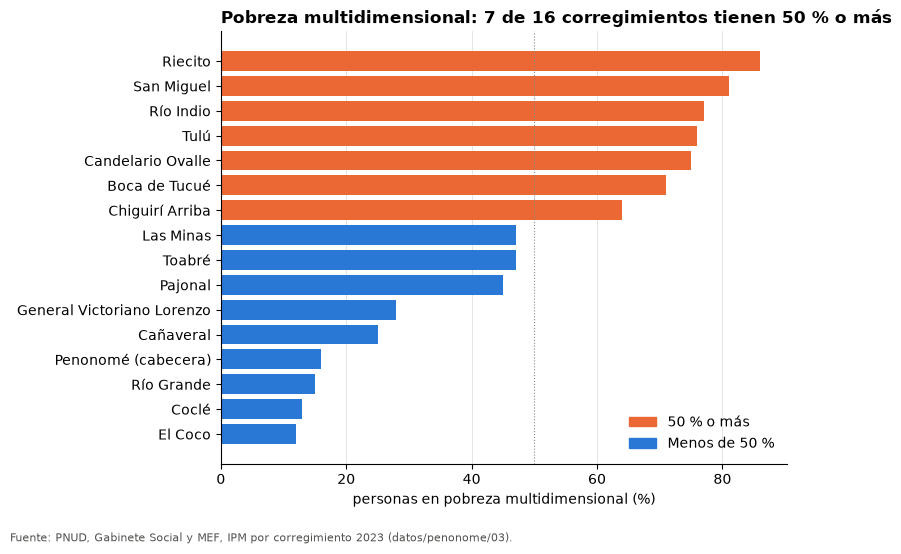

Correcto: corregimientos con 50 % o más de población en pobreza multidimensional
Correcto: el de mayor incidencia es Riecito
Correcto: el de menor incidencia es El Coco
Habitantes de esos 7 corregimientos: 22,510 (21.6 % del distrito)
Correcto: los siete pertenecen al bloque de la Ley 296
Correcto: habitantes de los siete corregimientos


In [16]:
from matplotlib.patches import Patch

orden_ipm = vulnerabilidad.sort_values("incidencia_ipm")
altos = int((orden_ipm["incidencia_ipm"] >= 50).sum())
colores = [an.NARANJA if x >= 50 else an.AZUL for x in orden_ipm["incidencia_ipm"]]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(orden_ipm.index, orden_ipm["incidencia_ipm"], color=colores)
ax.axvline(50, color="#898781", linewidth=0.8, linestyle=":")
ax.legend(handles=[Patch(color=an.NARANJA, label="50 % o más"), Patch(color=an.AZUL, label="Menos de 50 %")],
          frameon=False, loc="lower right")
an.estilo_eje(ax, f"Pobreza multidimensional: {altos} de 16 corregimientos tienen 50 % o más",
              "personas en pobreza multidimensional (%)", "",
              "PNUD, Gabinete Social y MEF, IPM por corregimiento 2023 (datos/penonome/03).")
ax.grid(True, axis="x", color="#e1e0d9", linewidth=0.6)
ax.grid(False, axis="y")
plt.show()

verificar("corregimientos con 50 % o más de población en pobreza multidimensional", altos, 7)
verificar("el de mayor incidencia es Riecito", orden_ipm.index[-1], "Riecito")
verificar("el de menor incidencia es El Coco", orden_ipm.index[0], "El Coco")

siete = vulnerabilidad[vulnerabilidad["incidencia_ipm"] >= 50]
nombres_bloque = set(tabla01.loc[sorted(del_bloque), "corregimiento"])      # los 11 corregimientos de la Ley 296
habitantes = int(siete["poblacion"].sum())
print(f"Habitantes de esos {altos} corregimientos: {habitantes:,} ({habitantes / vulnerabilidad['poblacion'].sum() * 100:.1f} % del distrito)")
verificar("los siete pertenecen al bloque de la Ley 296", set(siete.index) <= nombres_bloque, True)
verificar("habitantes de los siete corregimientos", habitantes, 22510)

La pobreza multidimensional va de 12 % en El Coco a 86 % en Riecito. Los siete corregimientos con 50 % o más (Riecito, San Miguel, Río Indio, Tulú, Candelario Ovalle, Boca de Tucué y Chiguirí Arriba) pertenecen todos al bloque de la Ley 296 de 2022, suman 22,510 habitantes y son el 21.6 % del distrito. La cabecera, con una de cada cuatro personas del distrito, tiene 16 %.

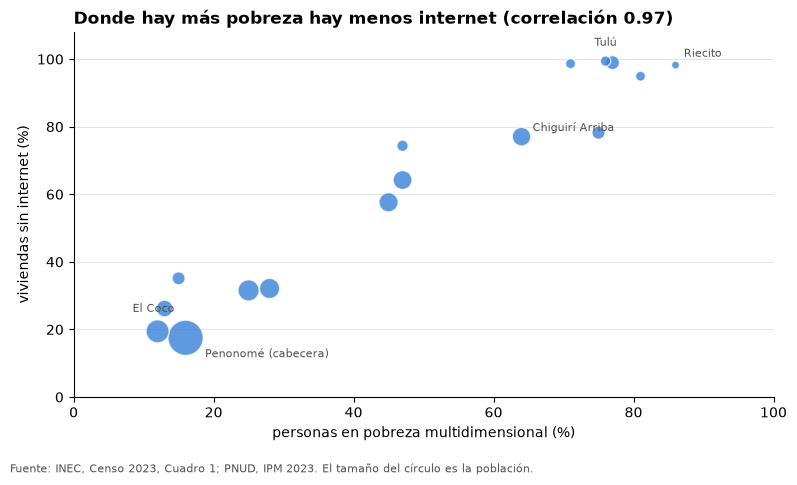

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(vulnerabilidad["incidencia_ipm"], vulnerabilidad["pct_sin_internet"],
           s=vulnerabilidad["poblacion"] / 40, color=an.AZUL, alpha=0.75, edgecolor="white")
desplazamiento = {"Riecito": (6, 6), "Tulú": (-8, 11), "Chiguirí Arriba": (8, 4),
                  "El Coco": (-18, 14), "Penonomé (cabecera)": (14, -14)}
for nombre, (dx, dy) in desplazamiento.items():
    fila = vulnerabilidad.loc[nombre]
    ax.annotate(nombre, (fila["incidencia_ipm"], fila["pct_sin_internet"]), textcoords="offset points",
                xytext=(dx, dy), fontsize=8, color="#52514e")
ax.set_xlim(0, 100)
ax.set_ylim(0, 108)
an.estilo_eje(ax, f"Donde hay más pobreza hay menos internet (correlación {correlacion['pct_sin_internet']:.2f})",
              "personas en pobreza multidimensional (%)", "viviendas sin internet (%)",
              "INEC, Censo 2023, Cuadro 1; PNUD, IPM 2023. El tamaño del círculo es la población.")
plt.show()

Cada círculo es un corregimiento. Los de mayor pobreza, como Riecito y Tulú, tienen más del 98 % de sus viviendas sin internet; la cabecera y El Coco, menos del 20 % (17.5 % y 19.4 %). La falta de internet sirve como señal rápida de rezago, pero sigue siendo un dato del Censo de 2023, anterior al sismo.

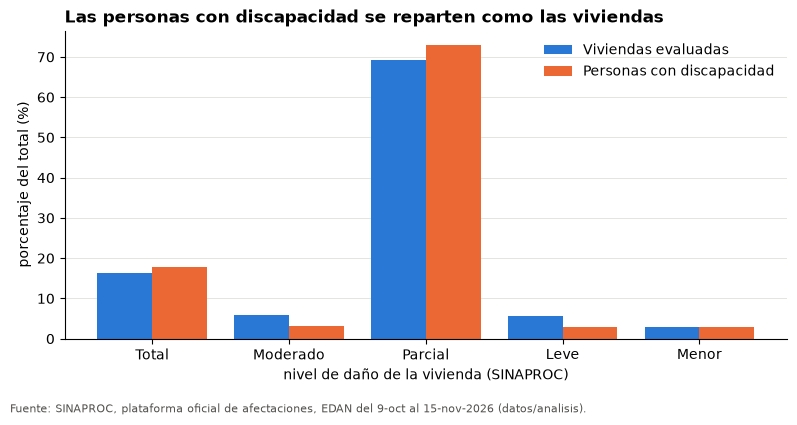

In [18]:
pct_viviendas = vulnerables["viviendas"] / vulnerables["viviendas"].sum() * 100
pct_discapacidad = vulnerables["Personas con discapacidad"] / vulnerables["Personas con discapacidad"].sum() * 100
posiciones = list(range(len(niveles)))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar([p - 0.2 for p in posiciones], pct_viviendas, width=0.4, color=an.AZUL, label="Viviendas evaluadas")
ax.bar([p + 0.2 for p in posiciones], pct_discapacidad, width=0.4, color=an.NARANJA, label="Personas con discapacidad")
ax.set_xticks(posiciones)
ax.set_xticklabels(niveles)
ax.legend(frameon=False, loc="upper right")
an.estilo_eje(ax, "Las personas con discapacidad se reparten como las viviendas",
              "nivel de daño de la vivienda (SINAPROC)", "porcentaje del total (%)",
              "SINAPROC, plataforma oficial de afectaciones, EDAN del 9-oct al 15-nov-2026 (datos/analisis).")
plt.show()

El nivel Parcial reúne el 69.1 % de las viviendas evaluadas y el 72.9 % de las personas con discapacidad; el nivel Total, el 16.4 % de las viviendas y el 17.9 % de esas personas. Las diferencias son de pocos puntos: la EDAN no muestra que la discapacidad se concentre en las viviendas con más daño, pero tampoco que quede al margen. La tabla de SINAPROC del proyecto es de toda la provincia de Coclé, no de Penonomé ni de cada corregimiento.

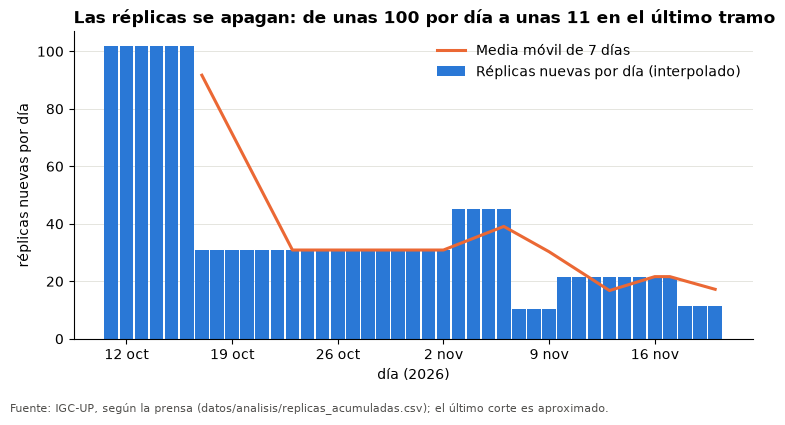

In [19]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(nuevas.index, nuevas, color=an.AZUL, width=0.9, label="Réplicas nuevas por día (interpolado)")
ax.plot(media_movil.index, media_movil, color=an.NARANJA, linewidth=2.2, label="Media móvil de 7 días")
ax.legend(frameon=False, loc="upper right")
an.estilo_eje(ax, "Las réplicas se apagan: de unas 100 por día a unas 11 en el último tramo",
              "día (2026)", "réplicas nuevas por día",
              "IGC-UP, según la prensa (datos/analisis/replicas_acumuladas.csv); el último corte es aproximado.")
marcas = pd.date_range("2026-10-12", "2026-11-20", freq="7D")
mes_corto = ("ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic")
ax.set_xticks(marcas)
ax.set_xticklabels([f"{d.day} {mes_corto[d.month - 1]}" for d in marcas])
plt.show()

Entre el 10 y el 16 de octubre el ritmo fue de unas 102 réplicas por día; entre el 17 y el 20 de noviembre, de unas 11. La media móvil suaviza los escalones, pero los escalones son un efecto de unir los cortes con rectas, no días reales.

Los registros de prensa por corregimiento (`registros_danos_corregimiento.csv`) son la única fuente del sismo con detalle por corregimiento, pero son registros, no unidades dañadas, y se asignaron por el nombre del lugar. Se ponen junto a la pobreza multidimensional solo para ver si coinciden:

In [20]:
registros = leer("registros_danos_corregimiento.csv", an.ANALISIS).set_index("corregimiento")["registros_danos"]
cruce = pd.DataFrame({"registros_prensa": registros, "incidencia_ipm": vulnerabilidad["incidencia_ipm"]})
cruce = cruce.sort_values("registros_prensa", ascending=False)
print(cruce.head(5))
print("Total de registros:", int(registros.sum()), "| corregimientos sin ningún registro:", int((registros == 0).sum()))

verificar("registros de prensa en total", int(registros.sum()), 43)
verificar("la cabecera concentra la mayoría de los registros", cruce.index[0], "Penonomé (cabecera)")

                     registros_prensa  incidencia_ipm
Penonomé (cabecera)                28              16
Toabré                              6              47
Río Grande                          2              15
Chiguirí Arriba                     1              64
Pajonal                             1              45
Total de registros: 43 | corregimientos sin ningún registro: 6
Correcto: registros de prensa en total
Correcto: la cabecera concentra la mayoría de los registros


La cabecera reúne 28 de los 43 registros (65 %) con una pobreza multidimensional de 16 %, y seis corregimientos no tienen ningún registro. No se puede concluir que el sismo golpeara menos a los corregimientos más pobres: los registros dependen de dónde hay población, prensa y reportes, y un corregimiento sin registro no es un corregimiento sin daño. Medir el efecto del sismo por corregimiento exige datos que hoy no existen en el proyecto.

## Conclusiones del proyecto

El proyecto responde a una pregunta real, la vulnerabilidad social de Penonomé antes del sismo del 9 de octubre de 2026 y las afectaciones sociales del sismo en Coclé, con datos oficiales verificados y con lo visto en las seis semanas del módulo de Python.

| Semana | Qué se aprendió | Dónde se aplicó |
|---|---|---|
| [1](s01-listas-diccionarios-conjuntos.ipynb) | Listas, tuplas, diccionarios, JSON y conjuntos | lectura de los CSV con el módulo `csv` (`penonome/carga.py`), CRUD del diccionario de corregimientos, conjuntos de corregimientos nuevos |
| [2](s02-funciones-clausuras-clases.ipynb) | Funciones, recursividad, clausuras y clases | funciones sobre los datos del Censo 2023, clases `Corregimiento` y `Fuente` (`penonome/modelos.py`) |
| [3](s03-pilas-colas-busqueda-hash.ipynb) | Pilas, colas, búsqueda y tablas hash | pila de correcciones del 24-nov-2026, cola de fuentes por verificar, índice hash de fuentes por URL |
| [4](s04-ordenamiento-greedy-divide-y-venceras.ipynb) | Ordenamiento, greedy y divide y vencerás | los cinco algoritmos sobre las 460 filas, prioridad de corregimientos con presupuesto, mejor tramo de las réplicas |
| [5](s05-dinamica-backtracking-modulos-pandas.ipynb) | Programación dinámica, retroceso, módulos, Series y DataFrames | mejor tramo por edad y sexo, reparto de brigadas con mochila memorizada, combinaciones de corregimientos, `penonome/analisis.py` |
| 6 | Datos ordenados, series temporales y miniproyectos | `pivot`/`melt` de la base larga y de las afectaciones de SINAPROC, `resample` y `rolling` de las réplicas, correlación de la vulnerabilidad y este análisis final |

### Hallazgos principales

1. Población: Penonomé tiene 104,326 habitantes (Censo 2023); la cabecera concentra uno de cada cuatro. Agrupado como pide la Ley 296, el bloque de los once corregimientos creció 11.8 % desde 2010 y El Coco casi se duplicó.
2. Vulnerabilidad previa: la pobreza multidimensional va de 12 % (El Coco) a 86 % (Riecito). Siete corregimientos, todos del bloque de la Ley 296 y con 22,510 habitantes, tienen 50 % o más, y la pobreza se mueve junto con la falta de internet (correlación 0.97), el piso de tierra (0.95) y la falta de agua potable (0.92).
3. Afectaciones en Coclé (SINAPROC, EDAN al 15 de noviembre): 2,531 viviendas evaluadas con 10,199 personas; 414 viviendas en el nivel de daño Total y 1,750 en el Parcial; 431 personas con discapacidad y 21 mujeres embarazadas, y 2,900 niñas, niños y adolescentes. Hay unas 17 personas con discapacidad por cada 100 viviendas evaluadas.
4. Seguimiento: los comunicados de SINAPROC contaron 149, 229 y 1,324 viviendas afectadas en menos de cuatro días (el último, preliminar), y las réplicas bajaron de unas 102 por día (10 al 16 de octubre) a unas 11 (17 al 20 de noviembre, corte aproximado).

### Límites

La tabla de SINAPROC es de toda la provincia de Coclé, no de cada corregimiento, así que no se puede cruzar el daño con la vulnerabilidad de cada uno; los registros de prensa por corregimiento son registros, no unidades dañadas. Los datos sociales por corregimiento (Censo 2023 y PNUD) son anteriores al sismo y no hay datos sociales posteriores a nivel de corregimiento. Las réplicas son datos de prensa y su último corte es aproximado. Los costos y las capacidades de los repartos de las semanas 4 y 5 son supuestos ilustrativos.

### Para seguir leyendo

- El documento completo del estudio, con todas las fuentes: [documento/estudio-penonome.md](../../documento/estudio-penonome.md).
- Las verificaciones contra las fuentes originales (carpeta `verificaciones/`): [paquetes de datos](../../investigacion/verificaciones/2026-11-24-paquetes-de-datos.md) y [documento](../../investigacion/verificaciones/2026-11-24-documento.md).
- El análisis principal del proyecto: [analisis-penonome.ipynb](../../analisis-penonome.ipynb).

[Proyecto](../../README.md) | [Anterior](s05-dinamica-backtracking-modulos-pandas.ipynb) | [Siguiente](../../README.md)